# Notebook 1 · CRISP-ML(Q) de punta a punta con FLAML + MLflow
**Curso:** Inteligencia Artificial — UTB · **Caso:** detección de tumores malignos (Breast Cancer Wisconsin, incluido en scikit-learn)

Este notebook recorre la **ruta clásica** del pipeline del curso, fase por fase:

| Fase CRISP-ML(Q) | Nodo(s) del pipeline | Qué haremos aquí |
|---|---|---|
| 1. Business & Data Understanding | *Business & Data Understanding (objetivos, KPIs, POC)* | Definir objetivo, KPIs y criterios de éxito **medibles** |
| 2. Data Engineering | *Data → Data Preprocessing → Feature Engineering → Train/Test/Validation Split* | Chequeos de calidad, huella del dataset, partición estratificada |
| 3. ML Model Engineering | *Feature Scaling → Model Selection → Hyperparameter Search → Machine Learning* | Línea base + AutoML con **FLAML**, todo registrado en **MLflow** |
| 4. ML Model Evaluation | *Test/Eval Set → Evaluation & QA* | Métricas, umbral de decisión, robustez, importancia, decisión *go/no-go* |
| 5. Deployment | *Deployment* | Registrar el modelo, alias `@champion`, cargarlo desde el registro |

> **Reproducibilidad:** semilla fija, huella SHA-256 del dataset, versiones de librerías y todos los parámetros/métricas/artefactos quedan en MLflow.

In [15]:
# !pip install "flaml[automl]" mlflow scikit-learn matplotlib   # ← descomentar en Colab
import os, sys, json, time, hashlib, platform, warnings
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["PYTHONWARNINGS"] = "ignore"          # silencia también a los procesos de joblib
warnings.filterwarnings("ignore")
import logging; logging.getLogger("mlflow").setLevel(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, flaml, mlflow
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from flaml import AutoML
from mlflow.models import infer_signature

SEED = 42                       # ← una sola semilla para TODO el experimento
np.random.seed(SEED)
mlflow.set_tracking_uri("sqlite:///mlflow.db")   # backend local con Model Registry
mlflow.set_experiment("NB1_crispmlq_breast_cancer")

VERSIONES = {"python": platform.python_version(), "sklearn": sklearn.__version__,
             "flaml": flaml.__version__, "mlflow": mlflow.__version__}
VERSIONES

{'python': '3.14.6', 'sklearn': '1.9.0', 'flaml': '2.6.0', 'mlflow': '3.17.2'}

## Fase 1 · Business & Data Understanding
**Objetivo de negocio:** priorizar biopsias para revisión urgente sin dejar pasar tumores malignos.

Criterios de éxito (CRISP-ML(Q) pide los tres tipos):
- **Negocio:** recall de la clase *maligno* ≥ 0.95 (un falso negativo es el error más costoso).
- **ML:** ROC-AUC ≥ 0.97 en test; precisión ≥ 0.85 con el umbral elegido.
- **Económico/operativo:** latencia de inferencia < 5 ms por caso en CPU.

**POC:** si una línea base simple ya cumple, el problema es viable con ML clásico.

In [16]:
CRITERIOS = {"recall_maligno_min": 0.95, "roc_auc_min": 0.97,
             "precision_min": 0.85, "latencia_ms_max": 5.0}
CRITERIOS

{'recall_maligno_min': 0.95,
 'roc_auc_min': 0.97,
 'precision_min': 0.85,
 'latencia_ms_max': 5.0}

## Fase 2 · Data Engineering
Nodos: **Data → Data Preprocessing → Preprocessed Data → Feature Engineering → Train/Test/Validation Split**

Medidas de QA de esta fase:
- Esquema y tipos esperados, valores faltantes, duplicados, balance de clases.
- **Huella del dataset (SHA-256)** para saber exactamente con qué datos se entrenó.
- Partición **estratificada 60/20/20** *antes* de cualquier ajuste (evita *data leakage*).

In [17]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = (1 - data.target).rename("maligno")   # en sklearn 0 = maligno → lo volvemos clase positiva (1)
X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [18]:


calidad = {
    "filas": X.shape[0], "columnas": X.shape[1],
    "faltantes": int(X.isna().sum().sum()),
    "duplicados": int(X.duplicated().sum()),
    "todas_numericas": bool(all(np.issubdtype(t, np.number) for t in X.dtypes)),
    "proporcion_maligno": round(float(y.mean()), 3),
}
assert calidad["faltantes"] == 0 and calidad["todas_numericas"], "Falla el control de calidad"
DATA_SHA256 = hashlib.sha256(pd.util.hash_pandas_object(pd.concat([X, y], axis=1), index=True).values.tobytes()).hexdigest()
calidad["sha256"] = DATA_SHA256[:16] + "…"
calidad

{'filas': 569,
 'columnas': 30,
 'faltantes': 0,
 'duplicados': 0,
 'todas_numericas': True,
 'proporcion_maligno': 0.373,
 'sha256': '4efa7cd9bc58e80e…'}

In [19]:
# Train / Validation / Test = 60 / 20 / 20, estratificado
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
pd.DataFrame({"n": [len(y_train), len(y_val), len(y_test)],
              "% maligno": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "val", "test"]).round(3)

,n,% maligno
train,341,0.372
val,114,0.377
test,114,0.368


## Fase 3 · ML Model Engineering — línea base
Nodos: **Feature Scaling → Train & Validation → Machine Learning**

La línea base es una regresión logística **dentro de un `Pipeline`**: el `StandardScaler` se ajusta solo con *train* (sin fuga de información).
Cada corrida queda en MLflow: parámetros, métricas, huella de datos y versiones.

In [20]:
with mlflow.start_run(run_name="baseline_logreg") as run_base:
    baseline = Pipeline([("scaler", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=5000, random_state=SEED))])
    baseline.fit(X_train, y_train)
    p_val = baseline.predict_proba(X_val)[:, 1]
    auc_base = roc_auc_score(y_val, p_val)
    mlflow.log_params({"modelo": "LogisticRegression+StandardScaler", "seed": SEED})
    mlflow.log_metric("val_roc_auc", auc_base)
    mlflow.set_tags({"fase": "3-model-engineering", "data_sha256": DATA_SHA256, **VERSIONES})
print(f"Línea base · ROC-AUC validación = {auc_base:.4f}")

Línea base · ROC-AUC validación = 0.9957


## Fase 3 · AutoML con FLAML (Model Selection + Hyperparameter Search)
FLAML resuelve el problema **CASH** (*Combined Algorithm Selection and Hyperparameter optimization*):
- **ECI** decide qué estimador probar a continuación (costo estimado para mejorar).
- **CFO / BlendSearch** recorren el espacio de hiperparámetros empezando por configuraciones **baratas**.
- Registramos en MLflow **un child run por estimador** (su mejor configuración y su ROC-AUC de CV).

> Nota de versiones: el registro automático de FLAML 2.7 (`mlflow_logging=True`) falla con MLflow 3.x porque este serializa con *skops* por defecto. Por eso se desactiva y se registra de forma explícita.

In [21]:
TIME_BUDGET = 60   # segundos; súbelo a 300 para una búsqueda más completa
automl = AutoML()
with mlflow.start_run(run_name="flaml_automl") as run_flaml:
    automl.fit(X_train, y_train, task="classification", metric="roc_auc",
               estimator_list=["lgbm", "xgboost", "rf", "extra_tree", "lrl1"],
               eval_method="cv", n_splits=5, time_budget=TIME_BUDGET, seed=SEED,
               log_file_name="flaml_nb1.log", verbose=0, mlflow_logging=False)
    for est, cfg in automl.best_config_per_estimator.items():      # child runs explícitos
        if cfg is None: continue
        with mlflow.start_run(run_name=f"flaml_{est}", nested=True):
            mlflow.log_params({"estimador": est, **{f"hp_{k}": v for k, v in cfg.items()}})
            mlflow.log_metric("cv_roc_auc", 1 - automl.best_loss_per_estimator[est])
    p_val_flaml = automl.predict_proba(X_val)[:, 1]
    auc_flaml = roc_auc_score(y_val, p_val_flaml)
    mlflow.log_params({"best_estimator": automl.best_estimator, "time_budget": TIME_BUDGET, "seed": SEED})
    mlflow.log_params({f"hp_{k}": v for k, v in automl.best_config.items()})
    mlflow.log_metrics({"cv_best_roc_auc": 1 - automl.best_loss, "val_roc_auc": auc_flaml})
    mlflow.set_tags({"fase": "3-model-engineering", "data_sha256": DATA_SHA256, **VERSIONES})

print("Mejor estimador:", automl.best_estimator)
print("Mejor configuración:", automl.best_config)
print(f"ROC-AUC CV = {1-automl.best_loss:.4f} · ROC-AUC validación = {auc_flaml:.4f} (línea base {auc_base:.4f})")
pd.Series({k: round(1 - v, 4) for k, v in automl.best_loss_per_estimator.items()}, name="mejor ROC-AUC CV por estimador")

Mejor estimador: lgbm
Mejor configuración: {'n_estimators': 47, 'num_leaves': 16, 'min_child_samples': 2, 'learning_rate': 1.0, 'log_max_bin': 8, 'colsample_bytree': np.float64(0.8740761563987862), 'reg_alpha': np.float64(0.01457852690163876), 'reg_lambda': np.float64(28.230308150297443)}
ROC-AUC CV = 0.9946 · ROC-AUC validación = 0.9931 (línea base 0.9957)


lgbm          0.9946
xgboost       0.9915
rf            0.9825
extra_tree    0.9912
lrl1          0.9333
Name: mejor ROC-AUC CV por estimador, dtype: float64

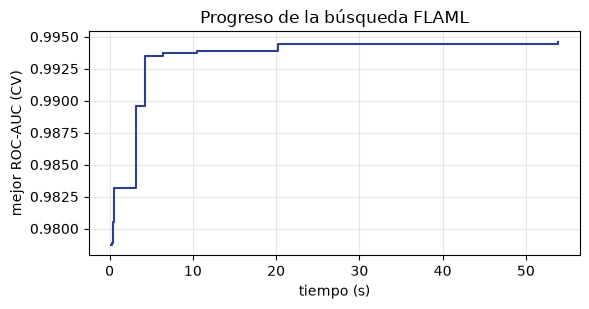

In [22]:
# Curva de búsqueda: cómo mejora la mejor configuración con el tiempo
from flaml.automl.data import get_output_from_log
t, loss, _, _, _ = get_output_from_log(filename="flaml_nb1.log", time_budget=TIME_BUDGET)
plt.figure(figsize=(6, 3.2))
plt.step(t, 1 - np.array(loss), where="post", color="#2E3F8F")
plt.xlabel("tiempo (s)"); plt.ylabel("mejor ROC-AUC (CV)"); plt.title("Progreso de la búsqueda FLAML")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## Fase 4 · ML Model Evaluation — iteración 1
Nodos: **Test / Eval Set → Evaluation & QA**

1. **Umbral de decisión** elegido en *validación* (no en test): el de mayor precisión que garantiza recall ≥ 0.95.
2. **Desempeño** en test · 3. **Robustez** (ruido gaussiano, 5 % de la desviación) · 4. **Latencia**.
5. **Decisión go/no-go** contra los criterios de la Fase 1.

In [23]:
def evaluar(modelo, umbral, X_ev, y_ev):
    # Devuelve métricas de desempeño, robustez y latencia para un modelo y un umbral
    p = modelo.predict_proba(X_ev)[:, 1]; yhat = (p >= umbral).astype(int)
    t0 = time.perf_counter(); modelo.predict_proba(X_ev); lat = (time.perf_counter() - t0) / len(X_ev) * 1000
    rng = np.random.default_rng(SEED)
    X_r = X_ev + rng.normal(0, 0.05 * X_train.std().values, X_ev.shape)
    return {"umbral": umbral, "test_roc_auc": roc_auc_score(y_ev, p), "test_recall": recall_score(y_ev, yhat),
            "test_precision": precision_score(y_ev, yhat), "test_f1": f1_score(y_ev, yhat),
            "test_roc_auc_con_ruido": roc_auc_score(y_ev, modelo.predict_proba(X_r)[:, 1]), "latencia_ms": lat}

def go_no_go(m):
    filas = [["Recall maligno", m["test_recall"], f"≥ {CRITERIOS['recall_maligno_min']}", m["test_recall"] >= CRITERIOS["recall_maligno_min"]],
             ["ROC-AUC", m["test_roc_auc"], f"≥ {CRITERIOS['roc_auc_min']}", m["test_roc_auc"] >= CRITERIOS["roc_auc_min"]],
             ["Precisión", m["test_precision"], f"≥ {CRITERIOS['precision_min']}", m["test_precision"] >= CRITERIOS["precision_min"]],
             ["Latencia (ms)", m["latencia_ms"], f"< {CRITERIOS['latencia_ms_max']}", m["latencia_ms"] < CRITERIOS["latencia_ms_max"]]]
    tabla = pd.DataFrame(filas, columns=["criterio", "valor", "meta", "cumple"])
    return bool(tabla["cumple"].all()), tabla

prec, rec, thr = precision_recall_curve(y_val, p_val_flaml)
ok = rec[:-1] >= CRITERIOS["recall_maligno_min"]
umbral_1 = float(thr[ok][np.argmax(prec[:-1][ok])])
metr_1 = evaluar(automl, umbral_1, X_test, y_test)
GO_1, tabla_1 = go_no_go(metr_1)
with mlflow.start_run(run_id=run_flaml.info.run_id):
    mlflow.log_metrics({k: v for k, v in metr_1.items() if k != "umbral"})
    mlflow.log_param("umbral_decision", round(umbral_1, 4))
    mlflow.set_tag("decision_go_no_go", "GO" if GO_1 else "NO-GO")
print("Iteración 1 (FLAML, umbral en validación):", "GO ✅" if GO_1 else "NO-GO ❌ → retroalimentación a Fase 3")
tabla_1.round(4)

Iteración 1 (FLAML, umbral en validación): NO-GO ❌ → retroalimentación a Fase 3


,criterio,valor,meta,cumple
0,Recall maligno,0.8810,≥ 0.95,False
1,ROC-AUC,0.9954,≥ 0.97,True
2,Precisión,1.0000,≥ 0.85,True
3,Latencia (ms),0.1151,< 5.0,True


### ¿Qué falló y qué dice CRISP-ML(Q)?
- El umbral se eligió con **solo 114 casos de validación** → estimación inestable del recall (**riesgo de varianza**).
- En validación, la **línea base** (ROC-AUC 0.996) iguala o supera a FLAML: AutoML **no garantiza** el mejor modelo.
- La flecha punteada del pipeline (*Evaluation → re-entrenamiento*) indica **volver a Model Engineering**, no "maquillar" el umbral sobre test.

## Fase 3 → 4 · Iteración 2 (bucle de retroalimentación)
Medidas de QA nuevas:
1. **Seleccionar el modelo** entre candidatos por ROC-AUC de validación (línea base vs. FLAML).
2. **Umbral con predicciones *out-of-fold*** (validación cruzada 5-fold sobre train+val = 455 casos) y **margen de seguridad**: recall objetivo 0.98.
3. Reentrenar sobre train+val y evaluar en test **una sola vez más**.

> En un proyecto real, después de mirar test en la iteración 1 haría falta un **test nuevo** (datos frescos). Aquí lo reutilizamos con fines didácticos.

In [24]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.base import clone

candidatos = {"baseline_logreg": (baseline, auc_base), f"flaml_{automl.best_estimator}": (automl.model.estimator, auc_flaml)}
nombre_sel = max(candidatos, key=lambda k: candidatos[k][1])
modelo_sel = clone(candidatos[nombre_sel][0])
print("Modelo seleccionado por ROC-AUC de validación:", nombre_sel)

X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(modelo_sel, X_tv, y_tv, cv=cv, method="predict_proba")[:, 1]
RECALL_OBJETIVO = 0.98                                  # margen sobre el 0.95 exigido
prec, rec, thr = precision_recall_curve(y_tv, oof)
UMBRAL = float(thr[rec[:-1] >= RECALL_OBJETIVO].max())

modelo_final = modelo_sel.fit(X_tv, y_tv)
metr = evaluar(modelo_final, UMBRAL, X_test, y_test)
GO, decision = go_no_go(metr)
yhat = (modelo_final.predict_proba(X_test)[:, 1] >= UMBRAL).astype(int)
print(f"Umbral (OOF, recall objetivo {RECALL_OBJETIVO}) = {UMBRAL:.3f}")
print("Iteración 2:", "GO ✅" if GO else "NO-GO ❌")
decision.round(4)

Modelo seleccionado por ROC-AUC de validación: baseline_logreg
Umbral (OOF, recall objetivo 0.98) = 0.104
Iteración 2: GO ✅


,criterio,valor,meta,cumple
0,Recall maligno,0.9762,≥ 0.95,True
1,ROC-AUC,0.9960,≥ 0.97,True
2,Precisión,0.8913,≥ 0.85,True
3,Latencia (ms),0.0579,< 5.0,True


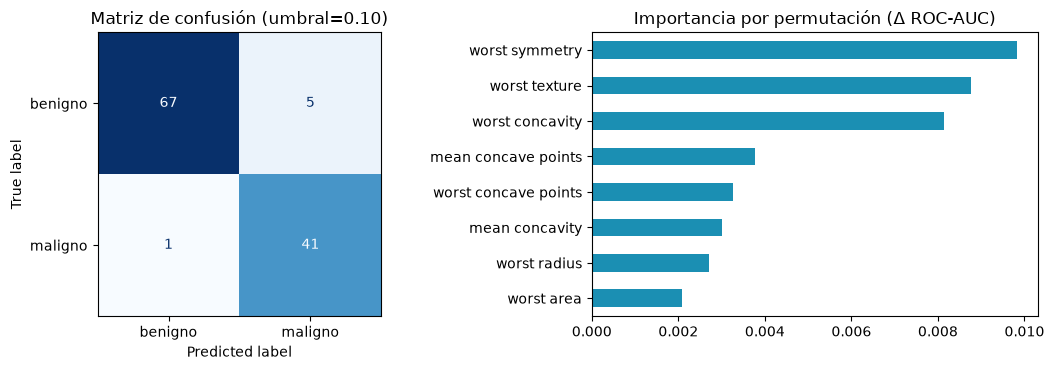

umbral                    0.1043
test_roc_auc              0.9960
test_recall               0.9762
test_precision            0.8913
test_f1                   0.9318
test_roc_auc_con_ruido    0.9967
latencia_ms               0.0579
dtype: float64

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, yhat), display_labels=["benigno", "maligno"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Matriz de confusión (umbral={UMBRAL:.2f})")
pi = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(8)
imp.plot.barh(ax=ax[1], color="#1B8FB3"); ax[1].set_title("Importancia por permutación (Δ ROC-AUC)")
plt.tight_layout(); plt.savefig("nb1_evaluacion.png", dpi=150); plt.show()

with mlflow.start_run(run_name=f"iteracion2_{nombre_sel}") as run_final:
    mlflow.log_params({"modelo": nombre_sel, "umbral_decision": round(UMBRAL, 4),
                       "recall_objetivo_oof": RECALL_OBJETIVO, "seed": SEED})
    mlflow.log_metrics({k: v for k, v in metr.items() if k != "umbral"})
    mlflow.log_artifact("nb1_evaluacion.png")
    mlflow.set_tags({"fase": "4-evaluation", "decision_go_no_go": "GO" if GO else "NO-GO",
                     "data_sha256": DATA_SHA256, **VERSIONES})
pd.Series(metr).round(4)

## Fase 5 · Deployment (preparación)
Nodo: **Deployment**. Solo si la decisión fue **GO**:
- Se registra el modelo con **firma** (esquema de entrada/salida) en el **Model Registry**.
- Se le asigna el alias **`@champion`**; producción siempre carga `models:/<nombre>@champion`.
- Cambiar de modelo = mover el alias (sin tocar el código de la aplicación).

In [26]:
NOMBRE = "nb1_cancer_clf"
firma = infer_signature(X_train, modelo_final.predict_proba(X_train)[:, 1])
with mlflow.start_run(run_id=run_final.info.run_id):
    info = mlflow.sklearn.log_model(sk_model=modelo_final, name="modelo", signature=firma,
                                    input_example=X_train.head(3), registered_model_name=NOMBRE,
                                    serialization_format="cloudpickle")  # MLflow 3 usa skops por defecto; LightGBM/XGBoost requieren cloudpickle
cliente = mlflow.MlflowClient()
version = info.registered_model_version
if GO:
    cliente.set_registered_model_alias(NOMBRE, "champion", version)
    cliente.set_model_version_tag(NOMBRE, version, "umbral_decision", f"{UMBRAL:.4f}")
print(f"Registrado {NOMBRE} v{version} · alias champion = {GO}")

2026/10/23 16:31:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Registrado nb1_cancer_clf v2 · alias champion = True


Registered model 'nb1_cancer_clf' already exists. Creating a new version of this model...
Created version '2' of model 'nb1_cancer_clf'.


In [27]:
# Consumo desde el registro, como lo haría el servicio en producción
ref = f"models:/{NOMBRE}@champion" if GO else f"models:/{NOMBRE}/{version}"   # sin GO no hay champion
print("Cargando", ref)
prod = mlflow.sklearn.load_model(ref)
umbral_prod = float(cliente.get_model_version(NOMBRE, version).tags.get("umbral_decision", UMBRAL))
nuevos = X_test.sample(5, random_state=SEED)
p = prod.predict_proba(nuevos)[:, 1]
pd.DataFrame({"p_maligno": p.round(3), "alerta": p >= umbral_prod,
              "real": y_test.loc[nuevos.index].values}, index=nuevos.index)

Cargando models:/nb1_cancer_clf@champion


,p_maligno,alerta,real
177,0.989,True,1
455,0.509,True,0
505,0.000,False,0
5,0.883,True,1
479,0.931,True,1


In [28]:
# Trazabilidad: todas las corridas del experimento
runs = mlflow.search_runs(experiment_names=["NB1_crispmlq_breast_cancer"])
cols = [c for c in ["tags.mlflow.runName", "metrics.cv_roc_auc", "metrics.val_roc_auc",
                    "metrics.test_recall", "metrics.test_roc_auc", "tags.decision_go_no_go"] if c in runs]
print("Corridas registradas:", len(runs))
runs[cols].round(4)

Corridas registradas: 15


,tags.mlflow.runName,metrics.cv_roc_auc,metrics.val_roc_auc,metrics.test_recall,metrics.test_roc_auc,tags.decision_go_no_go
0,iteracion2_baseline_logreg,NaN,NaN,0.9762,0.9960,GO
1,flaml_lrl1,0.9333,NaN,NaN,NaN,NaN
2,flaml_extra_tree,0.9912,NaN,NaN,NaN,NaN
3,flaml_rf,0.9825,NaN,NaN,NaN,NaN
4,flaml_xgboost,0.9915,NaN,NaN,NaN,NaN
5,flaml_lgbm,0.9946,NaN,NaN,NaN,NaN
6,flaml_automl,NaN,0.9931,0.8810,0.9954,NO-GO
7,baseline_logreg,NaN,0.9957,NaN,NaN,NaN
8,iteracion2_baseline_logreg,NaN,NaN,0.9762,0.9960,GO
9,flaml_extra_tree,0.9912,NaN,NaN,NaN,NaN


## Reflexión y extensiones
- Ejecuta `mlflow ui --backend-store-uri sqlite:///mlflow.db` y compara las corridas en la interfaz.
- Cambia `SEED` y repite: ¿cambia el mejor estimador? ¿cambian las métricas de test? (→ varianza del proceso).
- Sube `TIME_BUDGET` a 300 s: ¿mejora el ROC-AUC o solo el costo?
- `time_budget` hace que la búsqueda dependa del hardware (un PC más rápido prueba más configuraciones). Para reproducibilidad estricta usa `max_iter` en lugar de tiempo.
- ¿Qué riesgo de **equidad** (fairness) habría si el dataset tuviera variables demográficas?
- **Ruta LLM:** ¿qué nodos del pipeline cambiarían si el insumo fueran informes de patología en texto libre?